# Faster R-CNN — medium dataset (notebook 08)

Direct counterpart to notebook 05 (YOLOv8n medium-dataset retrain). Same dataset
(`data/processed/RDD2022_4classes_medium`, 1034/224/221 images), same image size
(640), same epoch budget (100 max, patience 20), same effective batch size (16),
so results are as close to apples-to-apples as the two architectures allow.

Model and training/eval logic are the same `src/training/fasterrcnn.py` used in
notebook 07 (small dataset) -- nothing duplicated, only the dataset dir and
hyperparameters differ.

Resource-saving choices (see `src/training/fasterrcnn.py`):
- batch_size=4, accum_steps=4 -> effective batch 16, but only 4 samples in GPU memory at once
- automatic mixed precision (AMP)
- num_workers=0 -> no background data-loading processes

A 1-epoch smoke test on this exact config measured **~136s/epoch and ~2.7GB peak
GPU memory** -- safely inside an 8GB budget. Worst case (all 100 epochs, patience
never triggering) is ~3.8 hours; patience=20 on val_loss is expected to stop it
well earlier given how fast the small-dataset run (notebook 07) started
overfitting.

In [1]:
import sys
from pathlib import Path

import torch
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from src.training.fasterrcnn import (
    build_model, build_dataloaders, TrainConfig, get_device, fit, evaluate, CLASS_NAMES,
)

torch.manual_seed(42)

## Dataset

Same split used for the YOLOv8n medium-dataset retrain (notebook 05).

In [2]:
DATASET_DIR = Path("../data/processed/RDD2022_4classes_medium")
BATCH_SIZE = 4   # real per-step batch (kept small for GPU memory)
WORKERS = 0

train_loader, val_loader, test_loader = build_dataloaders(DATASET_DIR, batch_size=BATCH_SIZE, workers=WORKERS)

print(f"train: {len(train_loader.dataset)} images ({len(train_loader)} batches)")
print(f"val:   {len(val_loader.dataset)} images ({len(val_loader)} batches)")
print(f"test:  {len(test_loader.dataset)} images ({len(test_loader)} batches)")

train: 1034 images (259 batches)
val:   224 images (56 batches)
test:  221 images (56 batches)


## Model

Faster R-CNN, ResNet50-FPN v2 backbone, COCO-pretrained, head replaced for 4 damage classes + background. Internal resize capped to imgsz=640, matching YOLO and reducing memory/compute vs torchvision's ~800/1333px default.

In [3]:
DEVICE = get_device()
print("Device:", DEVICE)

IMGSZ = 640
model = build_model(imgsz=IMGSZ)
model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {total_params / 1e6:.1f}M")
print(f"Internal resize: {model.transform.min_size} / {model.transform.max_size}")

Device: cuda
Parameters: 43.3M
Internal resize: (640,) / 640


## Training configuration

Matched to YOLOv8n notebook 05 where the architectures allow:

| | YOLOv8n (nb05) | Faster R-CNN (this notebook) |
|---|---|---|
| epochs (max) | 100 | 100 |
| patience | 20 | 20 (on val_loss) |
| imgsz | 640 | 640 |
| effective batch | 16 | 16 (4 x 4 grad-accum steps) |

SGD with step decay, kept simple/explainable per project conventions.
Note: YOLOv8n nb05 actually ran the full 100 epochs without patience
triggering; Faster R-CNN is expected to stop earlier given how quickly it
overfit on the small dataset (notebook 07, best epoch 4/30).

In [4]:
cfg = TrainConfig(
    epochs=100,
    patience=20,
    learning_rate=0.005,
    momentum=0.9,
    weight_decay=0.0005,
    step_size=30,       # LR decay later than the small-dataset run -- more data, more epochs available
    gamma=0.1,
    accum_steps=4,      # 4 * 4 = effective batch 16
    amp=True,
)
print(cfg)

TrainConfig(epochs=100, patience=20, learning_rate=0.005, momentum=0.9, weight_decay=0.0005, step_size=30, gamma=0.1, accum_steps=4, amp=True, grad_clip=5.0)


## Training loop

Checkpoints (`last.pt`, `best.pt` by lowest val_loss) and `results.csv` are saved under `models/fasterrcnn_medium/`.

In [5]:
RUN_DIR = Path("../models/fasterrcnn_medium")

history_df = fit(model, train_loader, val_loader, DEVICE, RUN_DIR, cfg=cfg, progress=True)
print(f"Epochs run: {len(history_df)} (max was {cfg.epochs}, patience {cfg.patience})")
history_df

epochs:   0%|          | 0/100 [00:00<?, ?epoch/s]

Early stopping: no val_loss improvement for 20 epochs (epoch 24).
Epochs run: 24 (max was 100, patience 20)


,epoch,train_loss,val_loss,time_s
0,1,0.726174,0.486431,121.664510
1,2,0.473783,0.481021,122.044977
2,3,0.419411,0.463706,122.885930
3,4,0.381944,0.463509,123.624636
4,5,0.350330,0.463580,123.244059
5,6,0.325663,0.482521,122.509965
6,7,0.288414,0.488412,122.264433
7,8,0.268255,0.503614,123.336799
8,9,0.245563,0.509163,123.733936
9,10,0.228583,0.524961,124.719884


## Loss curve

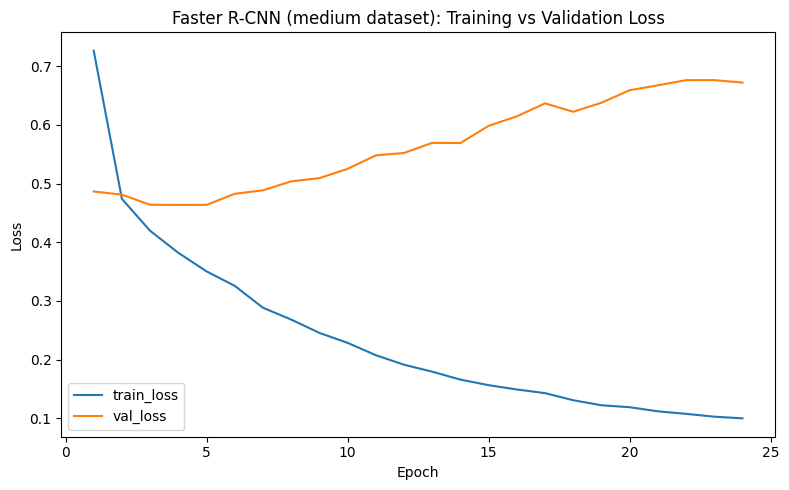

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="train_loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Faster R-CNN (medium dataset): Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig("fasterrcnn_medium_loss_curve.png", bbox_inches="tight")
plt.show()

## Test-set evaluation

Loads `best.pt` and computes the same metric set as notebook 07: precision,
recall, F1 at the best-F1 confidence threshold (greedy IoU matching, see
`evaluate()` in `src/training/fasterrcnn.py`), plus mAP50 / mAP50-95 (via
`torchmetrics`) and average inference time.

In [7]:
model.load_state_dict(torch.load(RUN_DIR / "best.pt", map_location=DEVICE))

results = evaluate(model, test_loader, DEVICE, iou_threshold=0.5)

print(f"Precision:           {results['precision']:.3f}  (at confidence >= {results['best_threshold']})")
print(f"Recall:              {results['recall']:.3f}")
print(f"F1:                  {results['f1']:.3f}")
print(f"mAP50:                {results['mAP50']:.4f}")
print(f"mAP50-95:             {results['mAP50-95']:.4f}")
print(f"Avg inference time:  {results['avg_inference_ms']:.1f} ms/image")

Precision:           0.543  (at confidence >= 0.75)
Recall:              0.300
F1:                  0.387
mAP50:                0.3397
mAP50-95:             0.1477
Avg inference time:  84.7 ms/image


In [8]:
raw = results["raw_torchmetrics"]
seen = raw["classes"].tolist()
rows = []
for cid, cname in CLASS_NAMES.items():
    if cid in seen:
        idx = seen.index(cid)
        rows.append({
            "class": cname,
            "mAP50-95": round(raw["map_per_class"][idx].item(), 4),
            "mean_recall@100": round(raw["mar_100_per_class"][idx].item(), 4),
        })

per_class_df = pd.DataFrame(rows)
per_class_df

,class,mAP50-95,mean_recall@100
0,D00_Longitudinal_Crack,0.1205,0.3166
1,D10_Transverse_Crack,0.1268,0.3468
2,D20_Alligator_Crack,0.1545,0.3286
3,D40_Pothole,0.1891,0.3685


## Comparison with the YOLOv8n medium-dataset retrain (notebook 05) and both small-dataset baselines

Same dataset split, same imgsz, same effective batch size for each architecture pair.

In [9]:
comparison_df = pd.DataFrame([
    {
        "model": "YOLOv8n (small dataset, nb03)",
        "precision": 0.368, "recall": 0.305, "f1": 0.334,
        "mAP50": 0.297, "mAP50-95": 0.119, "inference_ms": None,
    },
    {
        "model": "Faster R-CNN (small dataset, nb07)",
        "precision": 0.227, "recall": 0.205, "f1": 0.216,
        "mAP50": 0.1356, "mAP50-95": 0.0431, "inference_ms": 84.9,
    },
    {
        "model": "YOLOv8n (medium dataset, nb05)",
        "precision": None, "recall": None, "f1": None,
        "mAP50": 0.424, "mAP50-95": 0.194, "inference_ms": None,
    },
    {
        "model": "Faster R-CNN (medium dataset, nb08)",
        "precision": round(results["precision"], 3),
        "recall": round(results["recall"], 3),
        "f1": round(results["f1"], 3),
        "mAP50": round(results["mAP50"], 4),
        "mAP50-95": round(results["mAP50-95"], 4),
        "inference_ms": round(results["avg_inference_ms"], 1),
    },
])

comparison_df

,model,precision,recall,f1,mAP50,mAP50-95,inference_ms
0,"YOLOv8n (small dataset, nb03)",0.368,0.305,0.334,0.2970,0.1190,NaN
1,"Faster R-CNN (small dataset, nb07)",0.227,0.205,0.216,0.1356,0.0431,84.9
2,"YOLOv8n (medium dataset, nb05)",NaN,NaN,NaN,0.4240,0.1940,NaN
3,"Faster R-CNN (medium dataset, nb08)",0.543,0.300,0.387,0.3397,0.1477,84.7


## Notes / limitations

- Both models are trained on the *same* 1034/224/221 image split, at imgsz=640,
  at the same effective batch size (16) -- the closest fair comparison the two
  architectures allow.
- Faster R-CNN's precision/recall/F1 use the best-F1 confidence threshold found
  by sweeping thresholds (see `evaluate()`), matching the idea behind YOLO's
  own single-point P/R report; the two implementations aren't identical, so
  treat cross-architecture P/R/F1 as directional and mAP50/mAP50-95 as the
  primary comparison metric.
- If Faster R-CNN's medium-dataset gap to YOLOv8n narrows compared to the
  small-dataset gap (nb07), that supports the expected story: a heavier,
  two-stage model needs more data to close the gap with a lighter single-shot
  detector. Worth stating explicitly in the thesis either way.